# Experimentos finais

Este notebook reúne os experimentos principais do TCC sobre a versão 2 do dataset (`dataset/v2`, oito execuções do
cenário `evento_termico_v2`). A tarefa é identificar a fase do ambiente — `normal`, `pre_desastre`, `desastre` ou
`pos_desastre` — a cada consulta de um gateway a um sensor.

O experimento compara:

- **sete modelos**: os obrigatórios (Árvore de Decisão, Random Forest, Regressão Logística e KNN) e os opcionais
  SVM, Gradient Boosting e XGBoost;
- **quatro conjuntos de atributos**: sensores; sensores + bateria; sensores + rede; sensores + rede + bateria;
- **duas representações**: a consulta isolada e a consulta acompanhada de **janelas de 60 s** do próprio sensor e do
  gateway (o "modelo temporal simples com janelas" do plano).

Em todos os casos, o modelo é treinado com sete execuções e testado na oitava, que ele nunca viu, e as previsões das
oito rodadas são reunidas. Os entregáveis — tabela comparativa, matrizes de confusão, F1 por classe e análise de
erros — estão nas seções 4 a 8.

In [1]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from comum import (CLASSES, COR_CLASSE, DATASETS, NOMES_CLASSES, ORDEM_PAPEIS, REDE, RESULTADOS, SENSORES,
                   SEQUENCIAL, TAXA_BATERIA, TEXTO_SEC, aplicar_estilo, carregar_dados, salvar)
from janelas import JANELA_BATERIA, JANELA_REDE, JANELA_SENSORES, adicionar_atributos_janela

aplicar_estilo()
pd.set_option("display.precision", 3)
# Aviso interno do joblib, repetido a cada permutação; não afeta os resultados.
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
SEMENTE = 42
RESULTADOS.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 3.0.6


## 1. Dados e atributos

São usadas as 17.796 consultas da v2 (sem as 16 respostas que cruzaram fronteira de fase). Os atributos são só
medições que um gateway real teria; tempo, eventos, identificadores e papéis ficam de fora
(`cenarios/rotulacao.md`). A bateria entra como **taxa de descarga** (`battery_rate_pp_min`), e não como nível: o
notebook `03_comparacao_versoes.ipynb` mostrou que o nível funciona como um relógio e não generaliza entre execuções.

**Janelas de 60 s** (`janelas.py`). Cada consulta é decidida quando seu resultado fica conhecido — na chegada da
resposta ou ao fim do timeout de 15 s. Nesse instante, resumem-se as consultas dos 60 s anteriores cujo resultado já
era conhecido:

| Grupo | Consulta isolada | Acrescentado com janelas |
|:--|:--|:--|
| Sensores | `temperature`, `pressure` | temperatura média do sensor; temperatura média e máxima do gateway |
| Rede | `latency_ms`, `available`, `drop_rate` | latência média e disponibilidade do sensor; latência mediana e fração de falhas do gateway |
| Bateria | `battery_rate_pp_min` | taxa de descarga média do gateway |

Os atributos do gateway são o ponto central: um sensor de controle continua com leituras normais durante o desastre,
mas os vizinhos do mesmo gateway mostram calor, falhas e consumo maior.

In [2]:
dados = adicionar_atributos_janela(carregar_dados("v2"))
y = dados["label"].astype(str)
grupos = dados["run_id"].str[:11]
registro = json.loads((DATASETS / "v2" / "execucao.json").read_text(encoding="utf-8"))
print(f"{len(dados)} consultas, {grupos.nunique()} execuções")
y.value_counts().reindex(CLASSES).to_frame("exemplos")

17796 consultas, 8 execuções


,exemplos
label,
normal,6649
pre_desastre,3749
desastre,3675
pos_desastre,3723


In [3]:
# Conferência de causalidade: recalcula, para consultas sorteadas, a fração de falhas do gateway usando só as
# consultas cujo resultado era conhecido até o instante de decisão, e compara com o valor da janela.
from janelas import instante_decisao
decisao = instante_decisao(dados)
amostra = dados.sample(200, random_state=SEMENTE)
diferencas = []
for i, linha in amostra.iterrows():
    mesmo = (dados["run_id"] == linha["run_id"]) & (dados["gateway_id"] == linha["gateway_id"])
    janela = mesmo & (decisao > decisao[i] - 60e9) & (decisao <= decisao[i])
    diferencas.append(abs((1 - dados.loc[janela, "available"]).mean() - linha["gw_falhas_60s"]))
print(f"Maior diferença em 200 consultas sorteadas: {max(diferencas):.2e}")

Maior diferença em 200 consultas sorteadas: 0.00e+00


In [4]:
CONJUNTOS = {
    "Sensores": (SENSORES, JANELA_SENSORES),
    "Sensores + bateria": (SENSORES + TAXA_BATERIA, JANELA_SENSORES + JANELA_BATERIA),
    "Sensores + rede": (SENSORES + REDE, JANELA_SENSORES + JANELA_REDE),
    "Sensores + rede + bateria": (SENSORES + REDE + TAXA_BATERIA, JANELA_SENSORES + JANELA_REDE + JANELA_BATERIA),
}
REPRESENTACOES = ["Consulta isolada", "Com janelas de 60 s"]


def atributos(conjunto, representacao):
    base, janela = CONJUNTOS[conjunto]
    return base + (janela if representacao == REPRESENTACOES[1] else [])


pd.DataFrame({r: {c: len(atributos(c, r)) for c in CONJUNTOS} for r in REPRESENTACOES}).rename_axis("atributos")

,Consulta isolada,Com janelas de 60 s
atributos,,
Sensores,2,5
Sensores + bateria,3,7
Sensores + rede,5,12
Sensores + rede + bateria,6,14


## 2. Modelos

Todos os modelos ficam em um *pipeline* com imputação pela mediana e padronização, ajustadas só no treino de cada
rodada. Os hiperparâmetros iniciais são valores usuais, iguais para todas as combinações; a seção 5 ajusta os
hiperparâmetros da configuração principal com validação cruzada agrupada por execução.

In [5]:
class ComRotulosInteiros(BaseEstimator, ClassifierMixin):
    """Adapta classificadores que exigem rótulos 0..k-1 (XGBoost) para rótulos de texto."""

    def __init__(self, estimador):
        self.estimador = estimador

    def fit(self, X, y):
        self.classes_ = np.array(CLASSES)
        codigo = pd.Series(y).map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
        self.estimador_ = clone(self.estimador).fit(X, codigo)
        return self

    def predict(self, X):
        return self.classes_[self.estimador_.predict(X).astype(int)]

    def predict_proba(self, X):
        return self.estimador_.predict_proba(X)


MODELOS = {
    "Árvore de Decisão": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEMENTE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
    "Regressão Logística": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMENTE),
    "XGBoost": ComRotulosInteiros(XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                                                colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                                random_state=SEMENTE)),
}
OBRIGATORIOS = ["Árvore de Decisão", "Random Forest", "Regressão Logística", "KNN"]


def pipeline(modelo):
    return Pipeline([("imputacao", SimpleImputer(strategy="median")), ("padronizacao", StandardScaler()),
                     ("modelo", clone(modelo))])


RODADAS = list(LeaveOneGroupOut().split(dados, groups=grupos))


def prever(modelo, colunas):
    """Treina em sete execuções, prevê a oitava e reúne as previsões das oito rodadas."""
    partes = []
    for tr, te in RODADAS:
        pipe = pipeline(modelo).fit(dados.iloc[tr][colunas], y.iloc[tr])
        partes.append(pd.Series(pipe.predict(dados.iloc[te][colunas]), index=dados.index[te]))
    return pd.concat(partes).sort_index()

## 3. Comparação de modelos, conjuntos de atributos e representações

São 7 modelos × 4 conjuntos × 2 representações = 56 configurações, cada uma treinada oito vezes.

In [6]:
inicio = time.time()
previsoes, linhas = {}, []
for representacao in REPRESENTACOES:
    for conjunto in CONJUNTOS:
        colunas = atributos(conjunto, representacao)
        for nome, modelo in MODELOS.items():
            prev = prever(modelo, colunas)
            previsoes[(representacao, conjunto, nome)] = prev
            linhas.append({"representação": representacao, "conjunto": conjunto, "modelo": nome,
                           "F1 (macro)": f1_score(y, prev, average="macro"), "acurácia": accuracy_score(y, prev)})
grade = pd.DataFrame(linhas)
grade.to_csv(RESULTADOS / "finais_grade.csv", index=False, float_format="%.4f")
print(f"{len(grade)} configurações em {(time.time() - inicio) / 60:.1f} min")
grade.pivot_table(index=["representação", "conjunto"], columns="modelo", values="F1 (macro)",
                  sort=False)[list(MODELOS)].round(3)

56 configurações em 18.9 min


modelo                                         Árvore de Decisão  \
representação       conjunto                                       
Consulta isolada    Sensores                               0.323   
                    Sensores + bateria                     0.468   
                    Sensores + rede                        0.402   
                    Sensores + rede + bateria              0.493   
Com janelas de 60 s Sensores                               0.556   
                    Sensores + bateria                     0.697   
                    Sensores + rede                        0.657   
                    Sensores + rede + bateria              0.698   

modelo                                         Random Forest  \
representação       conjunto                                   
Consulta isolada    Sensores                           0.331   
                    Sensores + bateria                 0.498   
                    Sensores + rede                    0.443   
                    Sensores + rede + bateria          0.548   
Com janelas de 60 s Sensores                           0.648   
                    Sensores + bateria                 0.775   
                    Sensores + rede                    0.769   
                    Sensores + rede + bateria          0.818   

modelo                                         Regressão Logística    KNN  \
representação       conjunto                                                
Consulta isolada    Sensores                                 0.217  0.289   
                    Sensores + bateria                       0.386  0.428   
                    Sensores + rede                          0.437  0.419   
                    Sensores + rede + bateria                0.504  0.473   
Com janelas de 60 s Sensores                                 0.656  0.659   
                    Sensores + bateria                       0.760  0.740   
                    Sensores + rede                          0.736  0.746   
                    Sensores + rede + bateria                0.789  0.773   

modelo                                           SVM  Gradient Boosting  \
representação       conjunto                                              
Consulta isolada    Sensores                   0.276              0.345   
                    Sensores + bateria         0.409              0.510   
                    Sensores + rede            0.466              0.478   
                    Sensores + rede + bateria  0.526              0.554   
Com janelas de 60 s Sensores                   0.664              0.623   
                    Sensores + bateria         0.781              0.748   
                    Sensores + rede            0.761              0.726   
                    Sensores + rede + bateria  0.807              0.794   

modelo                                         XGBoost  
representação       conjunto                            
Consulta isolada    Sensores                     0.341  
                    Sensores + bateria           0.514  
                    Sensores + rede              0.462  
                    Sensores + rede + bateria    0.562  
Com janelas de 60 s Sensores                     0.628  
                    Sensores + bateria           0.752  
                    Sensores + rede              0.730  
                    Sensores + rede + bateria    0.790

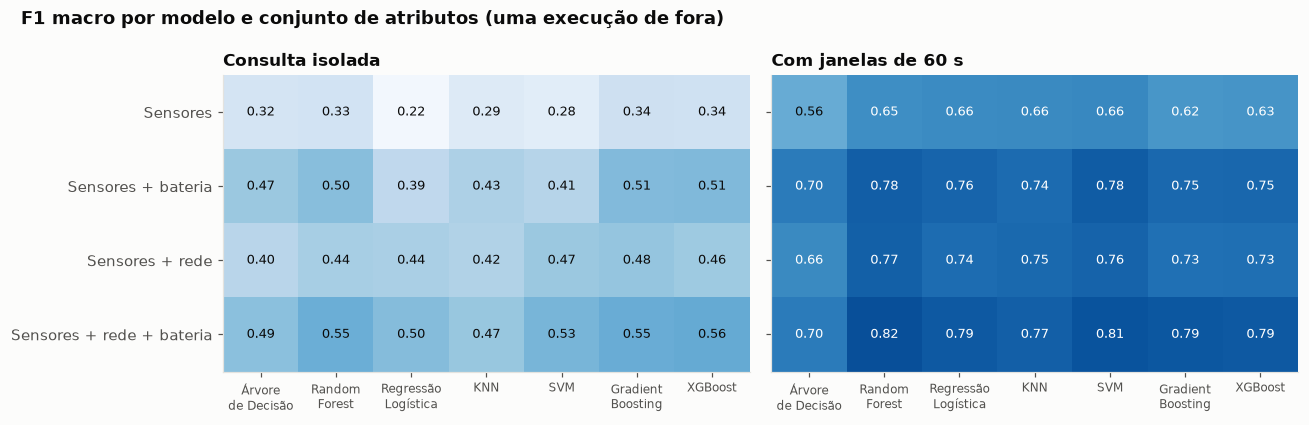

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, representacao in zip(eixos, REPRESENTACOES):
    tabela = (grade[grade["representação"] == representacao]
              .pivot(index="conjunto", columns="modelo", values="F1 (macro)").reindex(index=list(CONJUNTOS), columns=list(MODELOS)))
    ax.imshow(tabela.to_numpy(), cmap=SEQUENCIAL, vmin=0.2, vmax=0.9, aspect="auto")
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            v = tabela.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > 0.62 else "#0b0b0b")
    ax.set_xticks(range(len(MODELOS)), [m.replace(" ", "\n", 1) if len(m) > 12 else m for m in MODELOS], fontsize=8)
    ax.set_yticks(range(len(CONJUNTOS)), list(CONJUNTOS))
    ax.grid(False)
    ax.set_title(representacao)
fig.suptitle("F1 macro por modelo e conjunto de atributos (uma execução de fora)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "finais_grade_f1.png")
plt.show()

**Leitura da grade.**

- **As janelas são o maior ganho do experimento.** No conjunto completo, todos os modelos sobem de 0,20 a 0,30 no F1 macro: Random Forest de 0,55 para 0,82, SVM de 0,53 para 0,81, Regressão Logística de 0,50 para 0,79, KNN de 0,47 para 0,77. Olhar o gateway nos últimos 60 s dá ao modelo o estado do ambiente, que é o que o rótulo descreve.
- **Rede e bateria melhoram a classificação em todos os modelos.** Com janelas, só sensores dão de 0,56 a 0,66; com bateria, de 0,70 a 0,78; com rede, de 0,66 a 0,77; com tudo, de 0,70 a 0,82. O conjunto completo é o melhor para todos os modelos, e em seis dos sete a taxa de descarga acrescenta um pouco mais que os atributos de rede (a exceção é o KNN).
- **Os modelos ficam próximos entre si.** Com janelas, seis dos sete modelos ficam entre 0,77 e 0,82; só a Árvore de Decisão fica para trás (0,70). Sem janelas, os modelos de *boosting* eram os melhores (0,55–0,56); com janelas, Random Forest e SVM passam à frente.

## 4. Tabela comparativa dos modelos

Configuração principal: **sensores + rede + bateria, com janelas de 60 s**. Além das métricas sobre todas as
previsões reunidas, a tabela mostra a média e o desvio-padrão do F1 macro entre as sete execuções com desastre e a
taxa de **alarmes falsos** — a fração de consultas da fase `normal` classificadas como alguma fase de desastre —, na
execução sem desastre (`execucao_08`) e em todas as consultas normais.

In [8]:
PRINCIPAL = ("Com janelas de 60 s", "Sensores + rede + bateria")
COLUNAS = atributos(PRINCIPAL[1], PRINCIPAL[0])
com_desastre = [g for g in grupos.unique() if g != "execucao_08"]


def resumo(prev):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        por_execucao = [f1_score(y[grupos == g], prev[grupos == g], average="macro") for g in com_desastre]
    normal = y == "normal"
    sem_desastre = grupos == "execucao_08"
    return {
        "acurácia": accuracy_score(y, prev),
        "precisão (macro)": precision_score(y, prev, average="macro"),
        "revocação (macro)": recall_score(y, prev, average="macro"),
        "F1 (macro)": f1_score(y, prev, average="macro"),
        "F1 por execução (média)": np.mean(por_execucao),
        "F1 por execução (dp)": np.std(por_execucao),
        "alarmes falsos (execução sem desastre)": (prev[sem_desastre] != "normal").mean(),
        "alarmes falsos (todas as consultas normais)": (prev[normal] != "normal").mean(),
    }


comparativa = pd.DataFrame({nome: resumo(previsoes[(*PRINCIPAL, nome)]) for nome in MODELOS}).T
comparativa = comparativa.sort_values("F1 (macro)", ascending=False)
comparativa.to_csv(RESULTADOS / "finais_tabela_modelos.csv", float_format="%.4f")
comparativa.style.format("{:.3f}").background_gradient(cmap=SEQUENCIAL, subset=["F1 (macro)"])

,acurácia,precisão (macro),revocação (macro),F1 (macro),F1 por execução (média),F1 por execução (dp),alarmes falsos (execução sem desastre),alarmes falsos (todas as consultas normais)
Random Forest,0.839,0.822,0.817,0.818,0.806,0.036,0.020,0.049
SVM,0.832,0.827,0.801,0.807,0.796,0.029,0.000,0.006
Gradient Boosting,0.816,0.794,0.796,0.794,0.788,0.034,0.057,0.081
XGBoost,0.811,0.790,0.792,0.790,0.787,0.050,0.086,0.091
Regressão Logística,0.813,0.800,0.784,0.789,0.774,0.042,0.021,0.036
KNN,0.804,0.790,0.769,0.773,0.765,0.043,0.010,0.019
Árvore de Decisão,0.717,0.700,0.703,0.698,0.692,0.057,0.193,0.209


In [9]:
# Ganho das janelas, por modelo, no conjunto completo.
ganho = grade[grade["conjunto"] == PRINCIPAL[1]].pivot(index="modelo", columns="representação", values="F1 (macro)")
ganho = ganho[REPRESENTACOES].reindex(comparativa.index)
ganho["ganho"] = ganho[REPRESENTACOES[1]] - ganho[REPRESENTACOES[0]]
ganho.round(3)

representação,Consulta isolada,Com janelas de 60 s,ganho
Random Forest,0.548,0.818,0.270
SVM,0.526,0.807,0.281
Gradient Boosting,0.554,0.794,0.241
XGBoost,0.562,0.790,0.228
Regressão Logística,0.504,0.789,0.285
KNN,0.473,0.773,0.300
Árvore de Decisão,0.493,0.698,0.204


**Comparação dos modelos** (configuração principal, hiperparâmetros padrão):

- **Random Forest** tem o melhor resultado: F1 macro 0,82 e acurácia 0,84, com F1 médio de 0,81 ± 0,04 entre as execuções.
- **SVM** vem logo atrás (0,81) e é o mais conservador: nenhum alarme falso na execução sem desastre e 0,6% nas consultas normais em geral.
- **Gradient Boosting, XGBoost e Regressão Logística** ficam praticamente empatados (0,79). Os dois modelos de *boosting* dão mais alarmes falsos (6% a 9% na execução sem desastre).
- **KNN** obtém 0,77, e a **Árvore de Decisão**, 0,70, com cerca de 20% de alarmes falsos — uma única árvore se ajusta demais às sete execuções de treino.

O desvio entre execuções (0,03 a 0,06) é da mesma ordem das diferenças entre os seis primeiros modelos. Por isso, a ordem entre eles não deve ser lida como definitiva; a vantagem das janelas, de 0,20 a 0,30 em todos os modelos, é muito maior que essa variação.

## 5. Ajuste de hiperparâmetros

Para cada modelo, uma pequena grade de hiperparâmetros é escolhida **dentro do treino** de cada rodada, por validação
cruzada agrupada por execução (três partes formadas pelas sete execuções de treino). A execução de teste nunca
participa da escolha. Assim, o resultado continua sendo uma estimativa honesta para uma execução nova.

In [10]:
GRADES = {
    "Árvore de Decisão": {"modelo__min_samples_leaf": [5, 20, 50], "modelo__max_depth": [None, 10]},
    "Random Forest": {"modelo__min_samples_leaf": [1, 5, 20], "modelo__max_features": ["sqrt", 0.5]},
    "Regressão Logística": {"modelo__C": [0.1, 1.0, 10.0]},
    "KNN": {"modelo__n_neighbors": [5, 9, 15, 25, 50]},
    "SVM": {"modelo__C": [0.3, 1.0, 3.0]},
    "Gradient Boosting": {"modelo__learning_rate": [0.05, 0.1], "modelo__max_leaf_nodes": [15, 31]},
    "XGBoost": {"modelo__estimador__max_depth": [3, 6], "modelo__estimador__learning_rate": [0.05, 0.1]},
}

inicio = time.time()
ajustados, escolhas = {}, []
for nome, modelo in MODELOS.items():
    partes = []
    for k, (tr, te) in enumerate(RODADAS):
        busca = GridSearchCV(pipeline(modelo), GRADES[nome], scoring="f1_macro", cv=GroupKFold(n_splits=3), n_jobs=1)
        busca.fit(dados.iloc[tr][COLUNAS], y.iloc[tr], groups=grupos.iloc[tr])
        partes.append(pd.Series(busca.predict(dados.iloc[te][COLUNAS]), index=dados.index[te]))
        escolhas.append({"modelo": nome, "execução de teste": grupos.iloc[te].iloc[0],
                         **{k.split("__")[-1]: v for k, v in busca.best_params_.items()}})
    ajustados[nome] = pd.concat(partes).sort_index()
print(f"Ajuste concluído em {(time.time() - inicio) / 60:.1f} min")

comparacao_ajuste = pd.DataFrame({
    "F1 macro (padrão)": {n: f1_score(y, previsoes[(*PRINCIPAL, n)], average="macro") for n in MODELOS},
    "F1 macro (ajustado)": {n: f1_score(y, ajustados[n], average="macro") for n in MODELOS},
})
comparacao_ajuste["diferença"] = comparacao_ajuste.iloc[:, 1] - comparacao_ajuste.iloc[:, 0]
comparacao_ajuste.to_csv(RESULTADOS / "finais_ajuste.csv", float_format="%.4f")
comparacao_ajuste.sort_values("F1 macro (ajustado)", ascending=False).round(3)

Ajuste concluído em 27.0 min


,F1 macro (padrão),F1 macro (ajustado),diferença
Random Forest,0.818,0.816,-0.001
Gradient Boosting,0.794,0.804,0.009
SVM,0.807,0.803,-0.004
XGBoost,0.790,0.800,0.009
Regressão Logística,0.789,0.791,0.003
KNN,0.773,0.772,-0.001
Árvore de Decisão,0.698,0.693,-0.004


In [11]:
# Hiperparâmetros mais escolhidos nas oito rodadas.
from collections import Counter


def mais_frequentes(nome):
    """Valor mais escolhido de cada hiperparâmetro de um modelo, com o número de rodadas em que foi escolhido."""
    rodadas = [e for e in escolhas if e["modelo"] == nome]
    chaves = [k for k in rodadas[0] if k not in ("modelo", "execução de teste")]
    resultado = {}
    for chave in chaves:
        contagem = Counter(repr(e[chave]) for e in rodadas)
        texto, vezes = contagem.most_common(1)[0]
        valor = next(e[chave] for e in rodadas if repr(e[chave]) == texto)
        resultado[chave] = (valor, vezes)
    return resultado


pd.DataFrame(escolhas).to_csv(RESULTADOS / "finais_hiperparametros.csv", index=False)
pd.Series({nome: ", ".join(f"{k} = {v} ({n}/8)" for k, (v, n) in mais_frequentes(nome).items())
           for nome in MODELOS}, name="mais escolhido (rodadas)").to_frame()

,mais escolhido (rodadas)
Árvore de Decisão,"max_depth = 10 (4/8), min_samples_leaf = 20 (4/8)"
Random Forest,"max_features = sqrt (8/8), min_samples_leaf = ..."
Regressão Logística,C = 10.0 (8/8)
KNN,n_neighbors = 15 (5/8)
SVM,C = 3.0 (6/8)
Gradient Boosting,"learning_rate = 0.1 (4/8), max_leaf_nodes = 15..."
XGBoost,"learning_rate = 0.05 (6/8), max_depth = 3 (5/8)"


O ajuste mudou o F1 macro em no máximo 0,01, para cima ou para baixo (de −0,004 a +0,009). Os modelos de *boosting* foram os que mais ganharam (Gradient Boosting 0,80; XGBoost 0,80), e o Random Forest continuou à frente (0,82); Gradient Boosting e SVM trocaram de posição, separados por 0,001. As escolhas mais frequentes foram: Random Forest com `min_samples_leaf = 5`; SVM com `C = 3`; Regressão Logística com `C = 10`; KNN com 15 vizinhos (em cinco das oito rodadas; 25 em duas e 9 em uma, dentro da grade de 5 a 50); XGBoost com profundidade 3 e taxa de aprendizado 0,05. Os hiperparâmetros iniciais já eram adequados; o que melhora o resultado é a representação dos dados, não o ajuste fino.

## 6. Matrizes de confusão dos principais modelos

As quatro melhores configurações ajustadas, na configuração principal. Cada célula mostra a quantidade de consultas e
a porcentagem em relação à classe real.

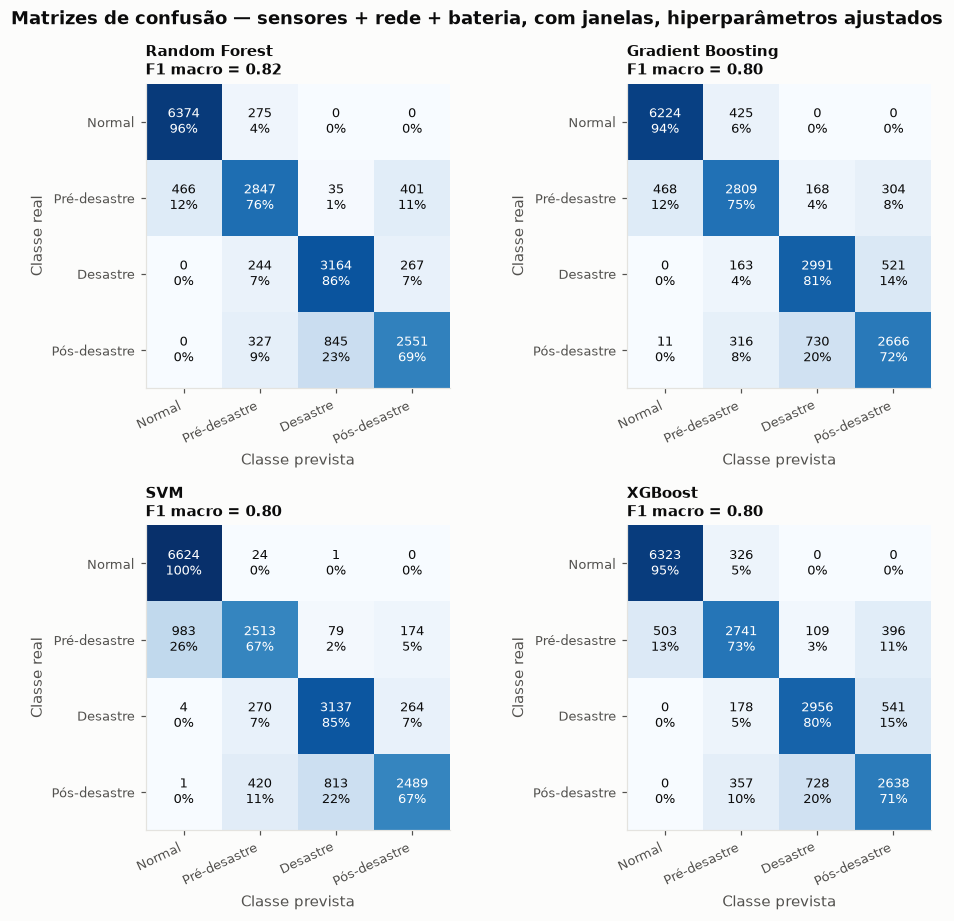

In [12]:
final = pd.DataFrame({
    "F1 (macro)": {n: f1_score(y, ajustados[n], average="macro") for n in MODELOS},
    "acurácia": {n: accuracy_score(y, ajustados[n]) for n in MODELOS},
}).sort_values("F1 (macro)", ascending=False)
PRINCIPAIS = list(final.index[:4])


def matriz(ax, prev, titulo):
    cm = confusion_matrix(y, prev, labels=CLASSES)
    taxa = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(taxa, cmap=SEQUENCIAL, vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]}\n{100 * taxa[i, j]:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if taxa[i, j] > 0.55 else "#0b0b0b")
    nomes = [NOMES_CLASSES[c] for c in CLASSES]
    ax.set_xticks(range(4), nomes, rotation=25, ha="right", fontsize=8.5)
    ax.set_yticks(range(4), nomes, fontsize=8.5)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
    ax.set_title(titulo, fontsize=10)


fig, eixos = plt.subplots(2, 2, figsize=(9, 8.5))
for ax, nome in zip(eixos.flat, PRINCIPAIS):
    matriz(ax, ajustados[nome], f"{nome}\nF1 macro = {final.loc[nome, 'F1 (macro)']:.2f}")
fig.suptitle("Matrizes de confusão — sensores + rede + bateria, com janelas, hiperparâmetros ajustados",
             x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "finais_matrizes_confusao.png")
plt.show()

Nas quatro matrizes, **normal quase nunca se confunde com desastre ou pós-desastre**, em nenhuma direção (no máximo 11 consultas). Os erros ficam entre fases vizinhas: o pós-desastre é confundido com o desastre (20% a 23%), o pré-desastre com o normal (12% a 26%) e com o pós-desastre (5% a 11%). O SVM é o mais conservador: reconhece 100% das consultas normais, mas deixa 26% do pré-desastre como normal. O Random Forest tem o melhor equilíbrio: 96% do normal, 76% do pré-desastre, 86% do desastre e 69% do pós-desastre.

## 7. F1-score por classe

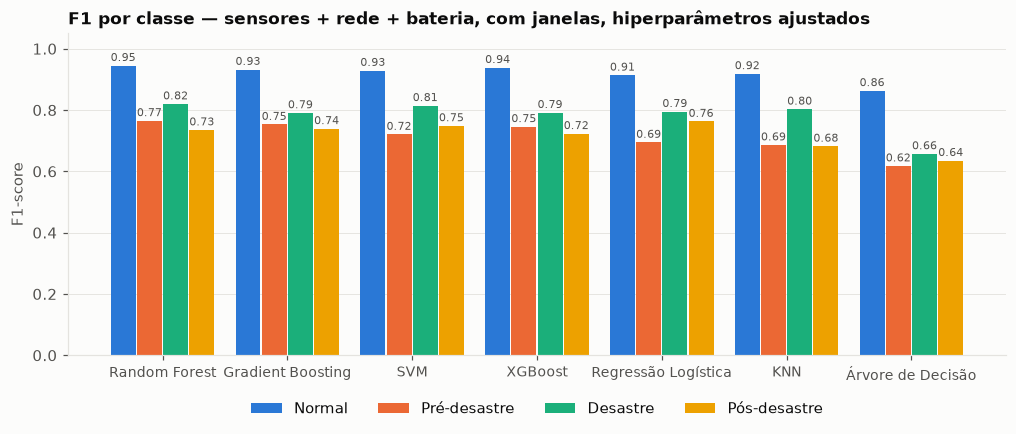

,normal,pre_desastre,desastre,pos_desastre
Random Forest,0.945,0.765,0.820,0.735
Gradient Boosting,0.932,0.753,0.791,0.739
SVM,0.929,0.720,0.814,0.749
XGBoost,0.938,0.746,0.792,0.723
Regressão Logística,0.914,0.694,0.795,0.763
KNN,0.918,0.686,0.803,0.682
Árvore de Decisão,0.863,0.617,0.657,0.635


In [13]:
f1_classes = pd.DataFrame({n: precision_recall_fscore_support(y, ajustados[n], labels=CLASSES, zero_division=0)[2]
                           for n in final.index}, index=CLASSES).T
f1_classes.to_csv(RESULTADOS / "finais_f1_por_classe.csv", float_format="%.4f")

fig, ax = plt.subplots(figsize=(11, 3.8))
largura = 0.2
for i, classe in enumerate(CLASSES):
    pos = np.arange(len(f1_classes)) + (i - 1.5) * (largura + 0.01)
    ax.bar(pos, f1_classes[classe], width=largura, color=COR_CLASSE[classe], label=NOMES_CLASSES[classe])
    for x, v in zip(pos, f1_classes[classe]):
        ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=TEXTO_SEC)
ax.set_xticks(range(len(f1_classes)), f1_classes.index, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-score")
ax.grid(axis="x", visible=False)
ax.set_title("F1 por classe — sensores + rede + bateria, com janelas, hiperparâmetros ajustados")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
salvar(fig, "finais_f1_por_classe.png")
plt.show()
f1_classes.round(3)

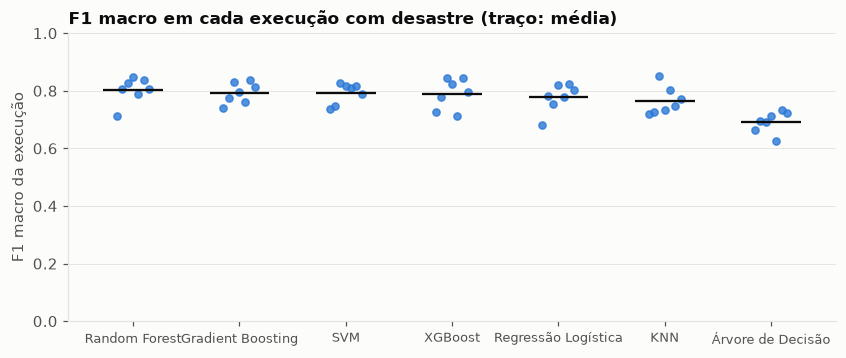

,Random Forest,Gradient Boosting,SVM,XGBoost,Regressão Logística,KNN,Árvore de Decisão
execucao_01,0.712,0.740,0.738,0.726,0.682,0.718,0.665
execucao_02,0.807,0.776,0.748,0.778,0.782,0.726,0.694
execucao_03,0.827,0.829,0.828,0.843,0.753,0.852,0.692
execucao_04,0.848,0.796,0.818,0.823,0.820,0.732,0.714
execucao_05,0.789,0.762,0.809,0.712,0.777,0.802,0.624
execucao_06,0.836,0.839,0.818,0.845,0.823,0.747,0.733
execucao_07,0.805,0.813,0.789,0.797,0.804,0.771,0.724


In [14]:
# Variação entre execuções: F1 macro de cada execução com desastre, por modelo.
por_execucao = pd.DataFrame({n: {g: f1_score(y[grupos == g], ajustados[n][grupos == g], average="macro")
                                 for g in com_desastre} for n in final.index})
fig, ax = plt.subplots(figsize=(9, 3.4))
for j, nome in enumerate(por_execucao.columns):
    ax.scatter(np.full(len(por_execucao), j) + np.linspace(-0.15, 0.15, len(por_execucao)), por_execucao[nome],
               s=22, color="#2a78d6", alpha=0.8, zorder=3)
    ax.hlines(por_execucao[nome].mean(), j - 0.28, j + 0.28, color="#0b0b0b", lw=1.5, zorder=4)
ax.set_xticks(range(len(por_execucao.columns)), por_execucao.columns, fontsize=8.5)
ax.set_ylabel("F1 macro da execução")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("F1 macro em cada execução com desastre (traço: média)")
salvar(fig, "finais_f1_por_execucao.png")
plt.show()
por_execucao.round(3)

**F1 por classe e por execução.** No Random Forest, a classe `normal` tem F1 de 0,95, o `desastre` 0,82, o `pre_desastre` 0,77 e o `pos_desastre` 0,74. Pré-desastre e pós-desastre são as classes mais difíceis em todos os modelos (F1 entre 0,62 e 0,77): o pré-desastre começa com uma degradação lenta, ainda parecida com o normal, e o pós-desastre começa com uma recuperação gradual, ainda parecida com o desastre. Entre execuções, o F1 macro do Random Forest vai de 0,71 a 0,85; a execução 01 é a mais difícil para cinco dos sete modelos.

## 8. Análise dos principais erros

A análise usa o melhor modelo ajustado e cruza suas previsões com metadados de auditoria que **não** entraram no
treino: papel do sensor, tempo desde o início da fase, perturbações benignas e a execução sem desastre.

In [15]:
MELHOR = final.index[0]
prev = ajustados[MELHOR]
analise = dados.assign(previsto=prev, acerto=(prev == y), execucao=grupos)
print(f"Melhor modelo: {MELHOR} (F1 macro {final.loc[MELHOR, 'F1 (macro)']:.3f})")

# Acerto por papel do sensor e fase, com e sem janelas (mesmo modelo, hiperparâmetros padrão).
isolada = previsoes[("Consulta isolada", PRINCIPAL[1], MELHOR)]
papeis = pd.concat({
    "consulta isolada": dados.assign(a=(isolada == y)).groupby(["papel", "label"], observed=True)["a"].mean().unstack(),
    "com janelas (ajustado)": analise.groupby(["papel", "label"], observed=True)["acerto"].mean().unstack(),
}).reindex(columns=CLASSES)
papeis.to_csv(RESULTADOS / "finais_acerto_por_papel.csv", float_format="%.4f")
papeis.style.format("{:.0%}", na_rep="—").background_gradient(cmap=SEQUENCIAL, vmin=0, vmax=1)

Melhor modelo: Random Forest (F1 macro 0.816)


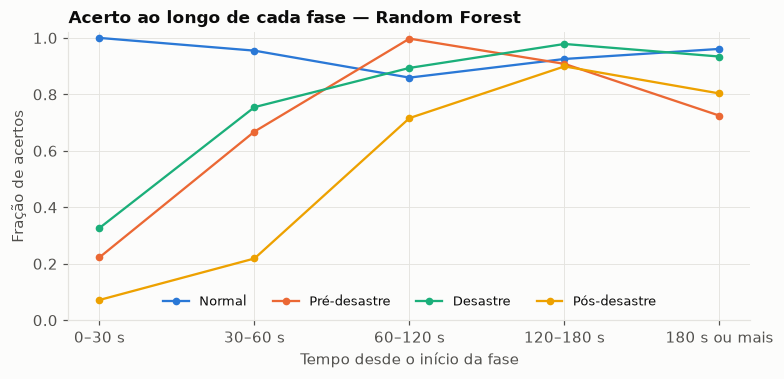

faixa,0–30 s,30–60 s,60–120 s,120–180 s,180 s ou mais
Normal,1.00,0.95,0.86,0.93,0.96
Pré-desastre,0.22,0.67,1.00,0.91,0.72
Desastre,0.33,0.75,0.89,0.98,0.93
Pós-desastre,0.07,0.22,0.72,0.90,0.80


In [16]:
# Erro em função do tempo desde o início da fase (execuções com desastre).
inicio_fase = {}
for e in registro["executions"]:
    for fase, (ini, _) in e["phases"].items():
        inicio_fase[(e["run_id"][:11], fase)] = ini
analise["desde_inicio_s"] = analise["elapsed_s"] - [inicio_fase[(g, l)] for g, l in zip(analise["execucao"], analise["label"])]
analise["faixa"] = pd.cut(analise["desde_inicio_s"], [0, 30, 60, 120, 180, 400], right=False,
                          labels=["0–30 s", "30–60 s", "60–120 s", "120–180 s", "180 s ou mais"])
por_tempo = (analise[analise["execucao"] != "execucao_08"]
             .groupby(["label", "faixa"], observed=True)["acerto"].mean().unstack().reindex(CLASSES))
por_tempo.index = [NOMES_CLASSES[c] for c in por_tempo.index]

fig, ax = plt.subplots(figsize=(8, 3.4))
for classe, linha in zip(CLASSES, por_tempo.itertuples(index=False)):
    ax.plot(por_tempo.columns.astype(str), linha, marker="o", ms=4, color=COR_CLASSE[classe], label=NOMES_CLASSES[classe])
ax.set_ylim(0, 1.02)
ax.set_ylabel("Fração de acertos")
ax.set_xlabel("Tempo desde o início da fase")
ax.set_title(f"Acerto ao longo de cada fase — {MELHOR}")
ax.legend(ncols=4, loc="lower center", fontsize=8.5)
salvar(fig, "finais_acerto_no_tempo.png")
plt.show()
por_tempo.round(2)

In [17]:
# Confusões mais frequentes e alarmes falsos.
erros = analise[~analise["acerto"]]
print("Confusões mais frequentes:")
display(erros.groupby(["label", "previsto"], observed=True).size().sort_values(ascending=False).head(6).to_frame("erros"))

sem_desastre = analise[analise["execucao"] == "execucao_08"]
print(f"Execução sem desastre: {(sem_desastre['previsto'] != 'normal').mean():.1%} de alarmes falsos "
      f"({(sem_desastre['previsto'] != 'normal').sum()} de {len(sem_desastre)} consultas)")
display(sem_desastre["previsto"].value_counts().to_frame("previsões"))

benigno = analise["event_name"].str.endswith("_benigno")
for nome, grupo in analise[benigno].groupby("event_name"):
    print(f"{nome}: {len(grupo)} consultas; classificadas como normal: {(grupo['previsto'] == 'normal').mean():.0%}")
normal_comum = analise[(analise["label"] == "normal") & ~benigno]
print(f"Consultas normais sem perturbação: {(normal_comum['previsto'] == 'normal').mean():.0%} classificadas como normal")

Confusões mais frequentes:


erros
label        previsto           
pos_desastre desastre        845
pre_desastre normal          466
             pos_desastre    401
pos_desastre pre_desastre    327
normal       pre_desastre    275
desastre     pos_desastre    267

Execução sem desastre: 0.6% de alarmes falsos (16 de 2575 consultas)


,previsões
previsto,
normal,2559
pre_desastre,16


aquecimento_local_benigno: 80 consultas; classificadas como normal: 80%
congestionamento_benigno: 70 consultas; classificadas como normal: 100%
Consultas normais sem perturbação: 96% classificadas como normal


### Importância dos atributos

Importância por permutação do melhor modelo: quanto o F1 macro cai quando um atributo é embaralhado na execução de
teste. É calculada nas oito rodadas, com os hiperparâmetros mais escolhidos no ajuste, e reportada como média.

Random Forest {'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 5}


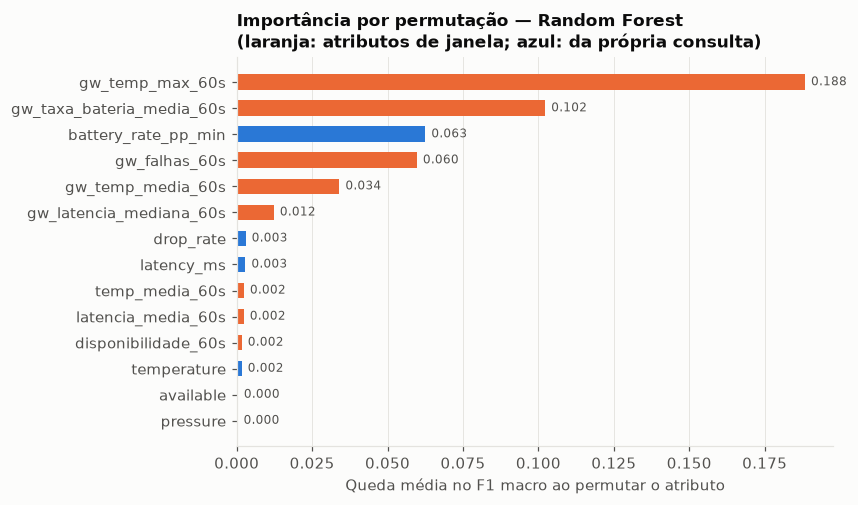

In [18]:
prefixo = "modelo__estimador__" if MELHOR == "XGBoost" else "modelo__"
mais_escolhidos = {prefixo + k: v for k, (v, _) in mais_frequentes(MELHOR).items()}
modelo_final = pipeline(MODELOS[MELHOR]).set_params(**mais_escolhidos)
print(MELHOR, mais_escolhidos)

importancias = []
for tr, te in RODADAS:
    pipe = clone(modelo_final).fit(dados.iloc[tr][COLUNAS], y.iloc[tr])
    r = permutation_importance(pipe, dados.iloc[te][COLUNAS], y.iloc[te], scoring="f1_macro", n_repeats=5,
                               random_state=SEMENTE, n_jobs=-1)
    importancias.append(pd.Series(r.importances_mean, index=COLUNAS))
importancia = pd.concat(importancias, axis=1).mean(axis=1).sort_values()
importancia.to_frame("queda média no F1 macro").to_csv(RESULTADOS / "finais_importancia.csv", float_format="%.4f")

fig, ax = plt.subplots(figsize=(7, 4.6))
cores = ["#eb6834" if c.startswith("gw_") or c.endswith("_60s") else "#2a78d6" for c in importancia.index]
ax.barh(importancia.index, importancia.values, color=cores, height=0.6)
for i, v in enumerate(importancia.values):
    ax.text(max(v, 0) + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=TEXTO_SEC)
ax.set_xlabel("Queda média no F1 macro ao permutar o atributo")
ax.grid(axis="y", visible=False)
ax.set_title(f"Importância por permutação — {MELHOR}\n(laranja: atributos de janela; azul: da própria consulta)")
salvar(fig, "finais_importancia.png")
plt.show()

**Principais erros e o que os explica** (Random Forest ajustado):

- **Os controles deixaram de ser o problema.** Com a consulta isolada, eles acertavam 5%, 2% e 3% do pré-desastre, do desastre e do pós-desastre; com as janelas do gateway, acertam 75%, 83% e 61%. Os sensores com falha energética passam de 39% para 86% de acerto no desastre, porque a falha deles agora é interpretada junto com o estado dos vizinhos.
- **Os erros restantes estão nas transições.** Nos primeiros 30 s de cada fase, o acerto é de 22% no pré-desastre, 33% no desastre e 7% no pós-desastre; depois de 60 a 120 s, passa de 70% em todas as fases. A janela de 60 s ainda contém a fase anterior, e os parâmetros mudam aos poucos (a transição de entrada no pré-desastre dura de 2 a 3 minutos). Isso explica as confusões mais frequentes: pós-desastre previsto como desastre (845) e pré-desastre previsto como normal (466). É um atraso de detecção de cerca de um minuto, inerente à janela.
- **Alarmes falsos são raros.** Na execução sem desastre, só 16 de 2.575 consultas (0,6%) foram classificadas como pré-desastre. Todos os congestionamentos benignos foram classificados como normais, e 80% das consultas durante aquecimentos locais também. Nas consultas normais sem perturbação, 96% são classificadas como normais.
- **Os atributos do gateway dominam.** A temperatura máxima do gateway em 60 s é de longe o atributo mais importante (queda de 0,19 no F1 macro ao embaralhá-lo), seguida da taxa de descarga média do gateway (0,10), da taxa de descarga do próprio sensor (0,06) e da fração de falhas do gateway (0,06). Os atributos individuais da consulta têm importância quase nula — não porque sejam inúteis, mas porque sua informação já está resumida nas janelas. A pressão continua sem importância, como esperado.

## 9. Conclusões

1. **Melhor configuração:** Random Forest com sensores, rede e taxa de bateria, com janelas de 60 s: F1 macro 0,82 e acurácia 0,84 em execuções nunca vistas no treino (hiperparâmetros padrão). Com os hiperparâmetros ajustados, o F1 macro se mantém em 0,82, e os alarmes falsos na execução sem desastre ficam em 0,6%. SVM, Gradient Boosting, XGBoost e Regressão Logística ficam entre 0,79 e 0,81 — diferenças da ordem da variação entre execuções.
2. **Representação importa mais que o algoritmo.** As janelas por sensor e por gateway aumentam o F1 macro em 0,20 a 0,30 em todos os modelos; o ajuste de hiperparâmetros muda no máximo 0,01, e a escolha entre os seis melhores algoritmos, no máximo 0,05.
3. **Atributos mais úteis:** temperatura máxima do gateway, consumo de bateria (taxa de descarga do sensor e do gateway) e fração de falhas do gateway. A inclusão de rede e bateria melhora a detecção em todos os modelos, com e sem janelas, o que responde à pergunta central do TCC.
4. **Limite atual:** um atraso de detecção de cerca de um minuto no início de cada fase, consequência da janela de 60 s.

**Limitações.** O cenário é sintético e sem calibração física; há oito execuções; a tarefa é de **detecção** do estado atual, não de antecipação; os hiperparâmetros foram ajustados apenas na configuração principal.

**Possíveis continuações.** Comparar janelas de 30, 60 e 120 s (troca entre atraso e estabilidade); implementar o alvo de antecipação já definido em `cenarios/rotulacao.md` ("estará em desastre daqui a 60 s?"); gerar mais execuções com outras sementes para estreitar as estimativas.